
# ST-HRPNet v1 — Patch-Balanced V2 Experiment

**Target paper:**  
**ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia**

Notebook V2 ini memperbaiki eksperimen sebelumnya yang mengalami pola prediksi **all-positive**. Perbaikan utama:

1. **Patch-balanced training** agar model belajar area HRP dan non-HRP secara seimbang.
2. **Dynamic input architecture** sehingga model dilatih pada patch 128×128 dan tetap dapat diinferensi pada citra penuh 256×256.
3. **Loss function anti-false-positive**: weighted BCE + Dice loss + false-positive penalty.
4. **Constrained threshold optimization** agar threshold tidak memilih solusi semua piksel positif.
5. **Metrik tambahan paper-ready**: IoU, Dice/F1, Precision, Recall, Specificity, FPR, Balanced Accuracy, MCC, PR-AUC, predicted positive ratio, dan inference time.
6. **Baseline comparison** tetap tersedia: U-Net 2D, ConvLSTM sederhana, dan 3D-CNN ringan.

Catatan ilmiah: Produk `HRP` dipakai sebagai pseudo-label dari JMA. Klaim aman adalah segmentasi **Himawari-derived Heavy Rainfall Potential**, bukan pengukuran curah hujan aktual.


In [2]:

# ============================================================
# 0. INSTALL LIBRARY
# ============================================================
# Jalankan jika library belum tersedia.
# Untuk Google Colab, buka komentar baris berikut.

# !pip install -q tensorflow opencv-python-headless requests beautifulsoup4 scikit-learn matplotlib pandas tqdm pillow

print("Library cell ready.")


Library cell ready.


In [3]:

# ============================================================
# 1. IMPORTS, SEED, DAN ENVIRONMENT CHECK
# ============================================================

import os
import re
import json
import time
import math
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin

import cv2
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from sklearn.metrics import precision_recall_curve, auc

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

try:
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)
except Exception as e:
    print("GPU memory growth skipped:", e)


TensorFlow version: 2.13.0
GPU devices: []


In [ ]:

# ============================================================
# 2. KONFIGURASI EKSPERIMEN V2
# ============================================================

PROJECT_NAME = "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2"
PAPER_TITLE = "ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia"

# URL resmi JMA, bukan Google Translate.
JMA_LIST_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html"
JMA_ROOT_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/"

# Input multispektral.
INPUT_PRODUCTS = ["b13", "b08", "b07", "b03"]

# Target utama wajib HRP.
TARGET_PRODUCT = "hrp"

# SND hanya untuk dokumentasi/validasi visual, bukan label utama.
OPTIONAL_PRODUCTS = ["snd"]

DOWNLOAD_PRODUCTS = []
for p in INPUT_PRODUCTS + [TARGET_PRODUCT] + OPTIONAL_PRODUCTS:
    if p not in DOWNLOAD_PRODUCTS:
        DOWNLOAD_PRODUCTS.append(p)

# Domain JMA r2w Southeast Asia Large.
DOMAIN_BBOX = {
    "lon_min": 90.0,
    "lon_max": 165.0,
    "lat_max": 30.0,
    "lat_min": -15.0,
}

# Crop Indonesia.
INDONESIA_BBOX = {
    "lon_min": 95.0,
    "lon_max": 141.0,
    "lat_max": 6.0,
    "lat_min": -11.0,
}

# Sequence temporal.
SEQ_LEN = 4

# Full image untuk evaluasi.
IMG_SIZE = (256, 256)

# Patch untuk training. Harus habis dibagi 8 karena pooling 3 level.
PATCH_SIZE = 128

# Jika None, semua timestamp lengkap pada halaman JMA diunduh.
MAX_TIMES = None

# Gunakan tag fixed jika ingin mengulang pada dataset sama.
DATASET_TAG = datetime.now(timezone.utc).strftime("jma_snapshot_%Y%m%d_%H%MUTC")

DATA_ROOT = Path("dataset_himawari_r2w")
RAW_DIR = DATA_ROOT / "raw" / DATASET_TAG
MANIFEST_DIR = DATA_ROOT / "manifests"
OUTPUT_DIR = Path("outputs") / PROJECT_NAME / DATASET_TAG

RAW_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Training setting.
BASE_FILTERS = 24
BATCH_SIZE = 8
EPOCHS_MAIN = 70
EPOCHS_BASELINE = 40
LEARNING_RATE = 7e-4

# Patch sampling.
N_TRAIN_PATCHES = 1800
N_VAL_PATCHES = 450
POSITIVE_PATCH_FRACTION = 0.65
MIN_POSITIVE_PIXELS = 16
NEGATIVE_MAX_POSITIVE_RATIO = 0.0005

# Baseline. Jika CPU sangat lambat, ubah menjadi False untuk uji cepat.
RUN_BASELINES = True

OVERWRITE_DOWNLOAD = False

print("Paper title:", PAPER_TITLE)
print("Download products:", DOWNLOAD_PRODUCTS)
print("Target product:", TARGET_PRODUCT)
print("Dataset tag:", DATASET_TAG)
print("Raw dir:", RAW_DIR)


Paper title: ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia
Download products: ['b13', 'b08', 'b07', 'b03', 'hrp', 'snd']
Target product: hrp
Dataset tag: jma_snapshot_20260529_0126UTC
Raw dir: dataset_himawari_r2w\raw\jma_snapshot_20260529_0126UTC


In [5]:

# ============================================================
# 3. DOWNLOAD DATA HIMAWARI R2W DARI JMA
# ============================================================

def safe_get(url, timeout=60, retries=3, sleep_sec=2):
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            return r
        except Exception as e:
            last_err = e
            print(f"[Retry {attempt}/{retries}] gagal akses {url}: {e}")
            time.sleep(sleep_sec)
    raise RuntimeError(f"Gagal akses setelah {retries} percobaan: {url}") from last_err


def parse_jma_r2w_list(list_url=JMA_LIST_URL, root_url=JMA_ROOT_URL):
    html = safe_get(list_url, timeout=60, retries=3).text
    soup = BeautifulSoup(html, "html.parser")
    rows = []
    pattern = re.compile(r"img/r2w/r2w_([a-z0-9]+)_(\d{4})\.jpg$", re.IGNORECASE)

    for a in soup.find_all("a", href=True):
        href = a["href"]
        m = pattern.search(href)
        if not m:
            continue
        product = m.group(1).lower()
        time_code = m.group(2)
        rows.append({
            "time_code": time_code,
            "product": product,
            "url": urljoin(root_url, href),
            "filename": f"r2w_{product}_{time_code}.jpg",
        })

    df = pd.DataFrame(rows).drop_duplicates()
    if df.empty:
        raise RuntimeError("Tidak ada link r2w yang berhasil diparse dari halaman JMA.")
    return df.sort_values(["time_code", "product"]).reset_index(drop=True)


def build_complete_table(df_links, products):
    pivot = df_links.pivot_table(index="time_code", columns="product", values="url", aggfunc="first")

    missing = [p for p in products if p not in pivot.columns]
    if missing:
        raise ValueError(f"Produk tidak ditemukan: {missing}. Produk tersedia: {sorted(df_links['product'].unique())}")

    complete = pivot.dropna(subset=products).reset_index()
    complete = complete[["time_code"] + products].sort_values("time_code").reset_index(drop=True)

    if MAX_TIMES is not None:
        complete = complete.head(int(MAX_TIMES)).copy()

    if complete.empty:
        raise RuntimeError("Tidak ada timestamp lengkap untuk produk yang diminta.")

    return complete


def is_valid_jpeg(path):
    path = Path(path)
    if (not path.exists()) or path.stat().st_size < 1024:
        return False
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img is not None and img.size > 0


def download_one(url, out_path, overwrite=False):
    out_path = Path(out_path)
    if out_path.exists() and (not overwrite) and is_valid_jpeg(out_path):
        return "exists"

    out_path.parent.mkdir(parents=True, exist_ok=True)
    r = safe_get(url, timeout=60, retries=3)
    out_path.write_bytes(r.content)

    if not is_valid_jpeg(out_path):
        raise RuntimeError(f"File tidak valid: {out_path}")

    return "downloaded"


def download_required_dataset(complete_df, products, raw_dir=RAW_DIR, overwrite=False):
    counters = {"downloaded": 0, "exists": 0, "failed": 0}
    errors = []

    pbar = tqdm(total=len(complete_df) * len(products), desc="Downloading Himawari files")
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        for product in products:
            url = row[product]
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            try:
                status = download_one(url, out_path, overwrite=overwrite)
                counters[status] += 1
            except Exception as e:
                counters["failed"] += 1
                errors.append({
                    "time_code": time_code,
                    "product": product,
                    "url": url,
                    "out_path": str(out_path),
                    "error": str(e),
                })
            pbar.update(1)
    pbar.close()

    rows = []
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        local = {"time_code": time_code}
        ok = True
        for product in products:
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            local[product] = str(out_path)
            local[f"{product}_url"] = row[product]
            if not is_valid_jpeg(out_path):
                ok = False
        local["is_complete_and_valid"] = ok
        rows.append(local)

    manifest = pd.DataFrame(rows)
    error_df = pd.DataFrame(errors)
    return manifest, counters, error_df


df_links = parse_jma_r2w_list()
print("Produk tersedia:", sorted(df_links["product"].unique()))
print("Jumlah link ditemukan:", len(df_links))

complete_table = build_complete_table(df_links, DOWNLOAD_PRODUCTS)
print("Jumlah timestamp lengkap:", len(complete_table))
display(complete_table.head())

manifest, counters, error_df = download_required_dataset(
    complete_table,
    DOWNLOAD_PRODUCTS,
    RAW_DIR,
    overwrite=OVERWRITE_DOWNLOAD,
)

manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"
manifest.to_csv(manifest_path, index=False)

if not error_df.empty:
    error_path = MANIFEST_DIR / f"download_errors_{DATASET_TAG}.csv"
    error_df.to_csv(error_path, index=False)
    print("Error log saved:", error_path)

print("Download counters:", counters)
print("Manifest saved:", manifest_path)
display(manifest.head())

valid_manifest = manifest[manifest["is_complete_and_valid"]].reset_index(drop=True)
if valid_manifest.empty:
    raise RuntimeError("Tidak ada file valid. Cek koneksi/download.")

print("Valid timestamps:", len(valid_manifest))


Produk tersedia: ['arm', 'b03', 'b07', 'b08', 'b13', 'cve', 'dms', 'dnc', 'dsl', 'dst', 'hrp', 'irv', 'ngt', 'snd', 'tre', 'trm', 'vir']
Jumlah link ditemukan: 2414
Jumlah timestamp lengkap: 142


product,time_code,b13,b08,b07,b03,hrp,snd
0,0000,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
1,0010,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
2,0020,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
3,0030,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
4,0040,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...


Download counters: {'downloaded': 852, 'exists': 0, 'failed': 0}
Manifest saved: dataset_himawari_r2w\manifests\manifest_jma_snapshot_20260529_0126UTC.csv


,time_code,b13,b13_url,b08,b08_url,b07,b07_url,b03,b03_url,hrp,hrp_url,snd,snd_url,is_complete_and_valid
0,0000,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
1,0010,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
2,0020,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
3,0030,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
4,0040,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260529...,https://www.data.jma.go.jp/mscweb/data/himawar...,True


Valid timestamps: 142


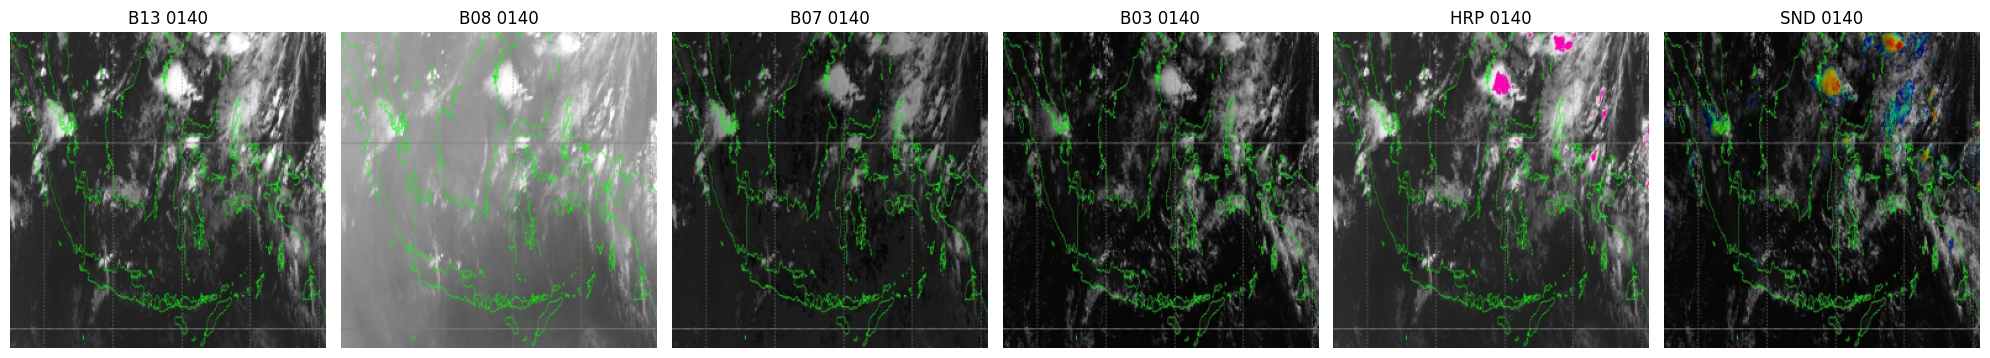

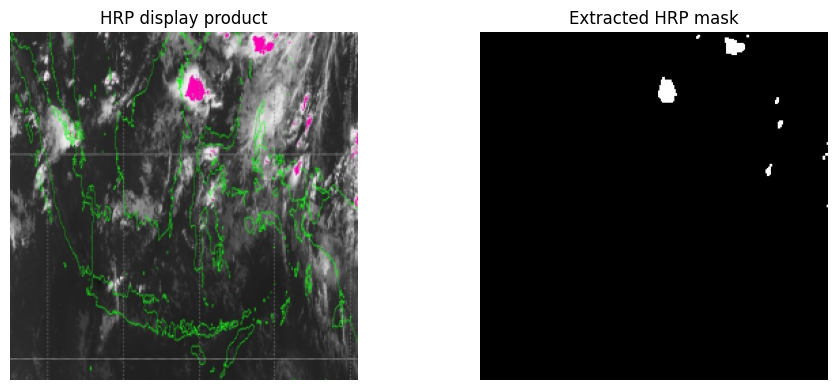

Sample positive pixel ratio: 0.00616455078125


In [6]:

# ============================================================
# 4. PREPROCESSING: CROP INDONESIA, INPUT CHANNEL, DAN MASK HRP
# ============================================================

def read_rgb(path):
    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise FileNotFoundError(f"Tidak bisa membaca gambar: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def lonlat_to_pixel(lon, lat, width, height, domain=DOMAIN_BBOX):
    x = (lon - domain["lon_min"]) / (domain["lon_max"] - domain["lon_min"]) * width
    y = (domain["lat_max"] - lat) / (domain["lat_max"] - domain["lat_min"]) * height
    return int(round(x)), int(round(y))


def crop_bbox(img_rgb, bbox=INDONESIA_BBOX, domain=DOMAIN_BBOX):
    h, w = img_rgb.shape[:2]
    x1, y1 = lonlat_to_pixel(bbox["lon_min"], bbox["lat_max"], w, h, domain)
    x2, y2 = lonlat_to_pixel(bbox["lon_max"], bbox["lat_min"], w, h, domain)

    x1, x2 = sorted([max(0, x1), min(w, x2)])
    y1, y2 = sorted([max(0, y1), min(h, y2)])

    if x2 <= x1 or y2 <= y1:
        raise ValueError("BBOX crop tidak valid.")

    return img_rgb[y1:y2, x1:x2]


def resize_rgb(img_rgb, size=IMG_SIZE, interpolation=cv2.INTER_AREA):
    return cv2.resize(img_rgb, size, interpolation=interpolation)


def product_to_input_channel(path, product):
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    # Gray conversion untuk display-product JPG.
    gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY).astype("float32") / 255.0

    # Normalisasi ringan per produk agar rentang channel stabil.
    p2, p98 = np.percentile(gray, [2, 98])
    if p98 > p2:
        gray = np.clip((gray - p2) / (p98 - p2), 0.0, 1.0)

    return gray[..., None]


def extract_hrp_magenta_mask_from_rgb(rgb):
    """Mask HRP berdasarkan magenta.

    Kombinasi RGB + HSV dibuat lebih stabil dibanding threshold RGB saja.
    """
    r = rgb[..., 0].astype(np.int16)
    g = rgb[..., 1].astype(np.int16)
    b = rgb[..., 2].astype(np.int16)

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h = hsv[..., 0]
    s = hsv[..., 1]
    v = hsv[..., 2]

    # Magenta pada OpenCV HSV umumnya dekat H 140-170.
    magenta_rgb = (r >= 145) & (b >= 110) & (g <= 140) & ((r - g) >= 45) & ((b - g) >= 20)
    magenta_hsv = (s >= 50) & (v >= 80) & ((h >= 125) | (h <= 5))
    mask = magenta_rgb & magenta_hsv

    mask = mask.astype(np.uint8)

    # Bersihkan noise kecil. Jangan terlalu agresif agar area kecil tidak hilang.
    kernel_open = np.ones((2, 2), np.uint8)
    kernel_close = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close, iterations=1)

    return mask.astype("float32")


def target_to_mask(path, product=TARGET_PRODUCT):
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    if product.lower() != "hrp":
        raise ValueError("Notebook V2 dirancang untuk TARGET_PRODUCT='hrp'.")

    mask = extract_hrp_magenta_mask_from_rgb(resized)
    return mask[..., None]


# Preview data.
sample_idx = min(10, len(valid_manifest) - 1)
sample = valid_manifest.iloc[sample_idx]

plt.figure(figsize=(20, 4))
for i, product in enumerate(DOWNLOAD_PRODUCTS):
    rgb = resize_rgb(crop_bbox(read_rgb(sample[product])), IMG_SIZE)
    plt.subplot(1, len(DOWNLOAD_PRODUCTS), i + 1)
    plt.imshow(rgb)
    plt.title(f"{product.upper()} {sample['time_code']}")
    plt.axis("off")
plt.tight_layout()
plt.show()

hrp_rgb = resize_rgb(crop_bbox(read_rgb(sample[TARGET_PRODUCT])), IMG_SIZE)
hrp_mask = target_to_mask(sample[TARGET_PRODUCT])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(hrp_rgb)
plt.title("HRP display product")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(hrp_mask[..., 0], cmap="gray")
plt.title("Extracted HRP mask")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Sample positive pixel ratio:", float(hrp_mask.mean()))


In [7]:

# ============================================================
# 5. MEMBANGUN FULL SEQUENCE DATASET
# ============================================================

def build_sequences_from_manifest(df, seq_len=SEQ_LEN, input_products=INPUT_PRODUCTS, target_product=TARGET_PRODUCT):
    df = df[df["is_complete_and_valid"]].sort_values("time_code").reset_index(drop=True)

    if len(df) < seq_len:
        raise RuntimeError("Timestamp valid lebih sedikit dari SEQ_LEN.")

    X, y, meta_rows = [], [], []

    for end_idx in tqdm(range(seq_len - 1, len(df)), desc="Building full sequences"):
        seq_df = df.iloc[end_idx - seq_len + 1:end_idx + 1]
        target_row = df.iloc[end_idx]

        frames = []
        for _, row in seq_df.iterrows():
            channels = []
            for product in input_products:
                channels.append(product_to_input_channel(row[product], product))
            frames.append(np.concatenate(channels, axis=-1))

        X.append(np.stack(frames, axis=0))
        y.append(target_to_mask(target_row[target_product], product=target_product))
        meta_rows.append({
            "sequence_time_codes": ",".join(seq_df["time_code"].tolist()),
            "target_time_code": target_row["time_code"],
            "target_path": target_row[target_product],
        })

    X = np.asarray(X, dtype="float32")
    y = np.asarray(y, dtype="float32")
    meta = pd.DataFrame(meta_rows)

    return X, y, meta


X, y, meta = build_sequences_from_manifest(valid_manifest)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Overall positive pixel ratio:", float(y.mean()))

meta_path = OUTPUT_DIR / "sequence_metadata.csv"
meta.to_csv(meta_path, index=False)
print("Sequence metadata saved:", meta_path)

display(meta.head())


Building full sequences:   0%|          | 0/139 [00:00<?, ?it/s]

X shape: (139, 4, 256, 256, 4)
y shape: (139, 256, 256, 1)
Overall positive pixel ratio: 0.020628895610570908
Sequence metadata saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\sequence_metadata.csv


,sequence_time_codes,target_time_code,target_path
0,"0000,0010,0020,0030",0030,dataset_himawari_r2w\raw\jma_snapshot_20260529...
1,"0010,0020,0030,0040",0040,dataset_himawari_r2w\raw\jma_snapshot_20260529...
2,"0020,0030,0040,0050",0050,dataset_himawari_r2w\raw\jma_snapshot_20260529...
3,"0030,0040,0050,0100",0100,dataset_himawari_r2w\raw\jma_snapshot_20260529...
4,"0040,0050,0100,0110",0110,dataset_himawari_r2w\raw\jma_snapshot_20260529...


In [8]:

# ============================================================
# 6. TEMPORAL SPLIT
# ============================================================

def temporal_split(X, y, meta, train_ratio=0.70, val_ratio=0.15):
    n = len(X)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))

    X_train, y_train = X[:train_end], y[:train_end]
    X_val, y_val = X[train_end:val_end], y[train_end:val_end]
    X_test, y_test = X[val_end:], y[val_end:]

    meta_train = meta.iloc[:train_end].reset_index(drop=True)
    meta_val = meta.iloc[train_end:val_end].reset_index(drop=True)
    meta_test = meta.iloc[val_end:].reset_index(drop=True)

    if min(len(X_train), len(X_val), len(X_test)) <= 0:
        raise RuntimeError("Split menghasilkan data kosong.")

    return (X_train, y_train, meta_train), (X_val, y_val, meta_val), (X_test, y_test, meta_test)


(train_data, val_data, test_data) = temporal_split(X, y, meta)
X_train, y_train, meta_train = train_data
X_val, y_val, meta_val = val_data
X_test, y_test, meta_test = test_data

split_summary = pd.DataFrame([
    {"split": "train", "n": len(X_train), "positive_pixel_ratio": float(y_train.mean())},
    {"split": "validation", "n": len(X_val), "positive_pixel_ratio": float(y_val.mean())},
    {"split": "test", "n": len(X_test), "positive_pixel_ratio": float(y_test.mean())},
])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)


,split,n,positive_pixel_ratio
0,train,97,0.018517
1,validation,21,0.025724
2,test,21,0.025287


In [9]:

# ============================================================
# 7. PATCH-BALANCED SAMPLING
# ============================================================

def clamp_int(v, low, high):
    return int(max(low, min(high, v)))


def crop_patch_x_y(X_img, y_img, top, left, patch_size=PATCH_SIZE):
    x_patch = X_img[:, top:top+patch_size, left:left+patch_size, :]
    y_patch = y_img[top:top+patch_size, left:left+patch_size, :]
    return x_patch, y_patch


def sample_positive_patch(X_arr, y_arr, patch_size=PATCH_SIZE, min_positive_pixels=MIN_POSITIVE_PIXELS, max_trials=100):
    n, t, h, w, c = X_arr.shape
    pos_img_indices = np.where(y_arr.reshape(n, -1).sum(axis=1) >= min_positive_pixels)[0]
    if len(pos_img_indices) == 0:
        raise RuntimeError("Tidak ada citra dengan piksel HRP positif cukup untuk positive patch.")

    for _ in range(max_trials):
        idx = int(np.random.choice(pos_img_indices))
        ys, xs = np.where(y_arr[idx, ..., 0] > 0.5)
        if len(xs) == 0:
            continue

        k = np.random.randint(0, len(xs))
        cy, cx = int(ys[k]), int(xs[k])

        top = clamp_int(cy - patch_size // 2 + np.random.randint(-patch_size//4, patch_size//4 + 1), 0, h - patch_size)
        left = clamp_int(cx - patch_size // 2 + np.random.randint(-patch_size//4, patch_size//4 + 1), 0, w - patch_size)

        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        if yp.sum() >= min_positive_pixels:
            return xp, yp

    # Fallback.
    idx = int(np.random.choice(pos_img_indices))
    ys, xs = np.where(y_arr[idx, ..., 0] > 0.5)
    k = np.random.randint(0, len(xs))
    cy, cx = int(ys[k]), int(xs[k])
    top = clamp_int(cy - patch_size // 2, 0, h - patch_size)
    left = clamp_int(cx - patch_size // 2, 0, w - patch_size)
    return crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)


def sample_negative_patch(X_arr, y_arr, patch_size=PATCH_SIZE, max_positive_ratio=NEGATIVE_MAX_POSITIVE_RATIO, max_trials=200):
    n, t, h, w, c = X_arr.shape

    for _ in range(max_trials):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)
        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        if float(yp.mean()) <= max_positive_ratio:
            return xp, yp

    # Fallback: cari patch dengan rasio positif terendah dari beberapa kandidat.
    best = None
    best_ratio = 1.0
    for _ in range(50):
        idx = np.random.randint(0, n)
        top = np.random.randint(0, h - patch_size + 1)
        left = np.random.randint(0, w - patch_size + 1)
        xp, yp = crop_patch_x_y(X_arr[idx], y_arr[idx], top, left, patch_size)
        ratio = float(yp.mean())
        if ratio < best_ratio:
            best_ratio = ratio
            best = (xp, yp)

    return best


def make_balanced_patches(X_arr, y_arr, n_patches, positive_fraction=POSITIVE_PATCH_FRACTION, patch_size=PATCH_SIZE):
    Xp, yp = [], []
    n_pos = int(round(n_patches * positive_fraction))
    n_neg = n_patches - n_pos

    for _ in tqdm(range(n_pos), desc="Positive patches"):
        x_patch, y_patch = sample_positive_patch(X_arr, y_arr, patch_size=patch_size)
        Xp.append(x_patch)
        yp.append(y_patch)

    for _ in tqdm(range(n_neg), desc="Negative patches"):
        x_patch, y_patch = sample_negative_patch(X_arr, y_arr, patch_size=patch_size)
        Xp.append(x_patch)
        yp.append(y_patch)

    Xp = np.asarray(Xp, dtype="float32")
    yp = np.asarray(yp, dtype="float32")

    order = np.random.permutation(len(Xp))
    return Xp[order], yp[order]


X_train_patch, y_train_patch = make_balanced_patches(X_train, y_train, N_TRAIN_PATCHES)
X_val_patch, y_val_patch = make_balanced_patches(X_val, y_val, N_VAL_PATCHES)

print("Train patch:", X_train_patch.shape, y_train_patch.shape, "positive ratio:", float(y_train_patch.mean()))
print("Val patch  :", X_val_patch.shape, y_val_patch.shape, "positive ratio:", float(y_val_patch.mean()))

patch_summary = pd.DataFrame([
    {"split": "train_patch", "n": len(X_train_patch), "positive_pixel_ratio": float(y_train_patch.mean())},
    {"split": "val_patch", "n": len(X_val_patch), "positive_pixel_ratio": float(y_val_patch.mean())},
])
display(patch_summary)
patch_summary.to_csv(OUTPUT_DIR / "patch_summary.csv", index=False)


Positive patches:   0%|          | 0/1170 [00:00<?, ?it/s]

Negative patches:   0%|          | 0/630 [00:00<?, ?it/s]

Positive patches:   0%|          | 0/292 [00:00<?, ?it/s]

Negative patches:   0%|          | 0/158 [00:00<?, ?it/s]

Train patch: (1800, 4, 128, 128, 4) (1800, 128, 128, 1) positive ratio: 0.021072998642921448
Val patch  : (450, 4, 128, 128, 4) (450, 128, 128, 1) positive ratio: 0.02783840522170067


,split,n,positive_pixel_ratio
0,train_patch,1800,0.021073
1,val_patch,450,0.027838


In [10]:

# ============================================================
# 8. TF.DATA PIPELINE
# ============================================================

def augment_sequence_and_mask(x, y):
    # Flip horizontal.
    if tf.random.uniform(()) > 0.5:
        x = tf.reverse(x, axis=[2])
        y = tf.reverse(y, axis=[1])

    # Flip vertical.
    if tf.random.uniform(()) > 0.5:
        x = tf.reverse(x, axis=[1])
        y = tf.reverse(y, axis=[0])

    # Brightness dan contrast kecil pada input.
    delta = tf.random.uniform((), minval=-0.03, maxval=0.03)
    x = tf.clip_by_value(x + delta, 0.0, 1.0)

    contrast = tf.random.uniform((), minval=0.95, maxval=1.05)
    x = tf.clip_by_value((x - 0.5) * contrast + 0.5, 0.0, 1.0)

    return x, y


def make_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(X_arr), 2048), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(augment_sequence_and_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_patch_ds = make_dataset(X_train_patch, y_train_patch, shuffle=True, augment=True)
val_patch_ds = make_dataset(X_val_patch, y_val_patch, shuffle=False, augment=False)

full_val_ds = make_dataset(X_val, y_val, batch_size=max(1, min(BATCH_SIZE, len(X_val))), shuffle=False, augment=False)
full_test_ds = make_dataset(X_test, y_test, batch_size=max(1, min(BATCH_SIZE, len(X_test))), shuffle=False, augment=False)

print("Dataset pipeline ready.")


Dataset pipeline ready.


In [11]:

# ============================================================
# 9. LOSS DAN METRICS V2
# ============================================================

SMOOTH = 1e-6

def compute_patch_pos_weight(y_patch, min_weight=2.0, max_weight=8.0):
    pos = float(y_patch.mean())
    if pos <= 0:
        return max_weight
    raw = math.sqrt((1.0 - pos) / pos)
    return float(np.clip(raw, min_weight, max_weight))


LOSS_POS_WEIGHT = compute_patch_pos_weight(y_train_patch)
print("LOSS_POS_WEIGHT:", LOSS_POS_WEIGHT)


def dice_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    denom = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    return (2.0 * inter + SMOOTH) / (denom + SMOOTH)


def iou_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - inter
    return (inter + SMOOTH) / (union + SMOOTH)


def weighted_bce_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-6, 1.0 - 1e-6)

    bce = keras.backend.binary_crossentropy(y_true, y_pred)
    weights = y_true * LOSS_POS_WEIGHT + (1.0 - y_true)
    return tf.reduce_mean(bce * weights)


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def false_positive_penalty(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    return tf.reduce_mean((1.0 - y_true) * y_pred)


def combined_hrp_loss(y_true, y_pred):
    # FP penalty dimasukkan untuk mencegah model kembali ke solusi all-positive.
    return 0.60 * weighted_bce_loss(y_true, y_pred) + 0.35 * dice_loss(y_true, y_pred) + 0.05 * false_positive_penalty(y_true, y_pred)


def precision_at_05(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fp = tf.reduce_sum((1.0 - y_true) * y_pred_bin)
    return (tp + SMOOTH) / (tp + fp + SMOOTH)


def recall_at_05(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fn = tf.reduce_sum(y_true * (1.0 - y_pred_bin))
    return (tp + SMOOTH) / (tp + fn + SMOOTH)


CUSTOM_OBJECTS = {
    "dice_coef": dice_coef,
    "iou_coef": iou_coef,
    "weighted_bce_loss": weighted_bce_loss,
    "dice_loss": dice_loss,
    "false_positive_penalty": false_positive_penalty,
    "combined_hrp_loss": combined_hrp_loss,
    "precision_at_05": precision_at_05,
    "recall_at_05": recall_at_05,
}


LOSS_POS_WEIGHT: 6.815723822580276


In [12]:

# ============================================================
# 10. MODEL DINAMIS: ST-HRPNet v1 Patch-Balanced
# ============================================================

def td_conv_block(x, filters, name, dropout=0.0):
    x = layers.TimeDistributed(
        layers.SeparableConv2D(filters, 3, padding="same", use_bias=False),
        name=f"{name}_sepconv1"
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_bn1")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_relu1")(x)

    x = layers.TimeDistributed(
        layers.SeparableConv2D(filters, 3, padding="same", use_bias=False),
        name=f"{name}_sepconv2"
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_bn2")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_relu2")(x)

    if dropout > 0:
        x = layers.TimeDistributed(layers.SpatialDropout2D(dropout), name=f"{name}_drop")(x)

    return x


def conv_block_2d(x, filters, name, dropout=0.0):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_sepconv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_sepconv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=f"{name}_drop")(x)

    return x


def last_time_step(x):
    return x[:, -1, ...]


def build_st_hrpnet_v1_patchbalanced(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inputs = keras.Input(shape=(seq_len, None, None, n_channels), name="himawari_sequence_dynamic")

    x1 = td_conv_block(inputs, base, "enc1", dropout=0.03)
    p1 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool1")(x1)

    x2 = td_conv_block(p1, base * 2, "enc2", dropout=0.05)
    p2 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool2")(x2)

    x3 = td_conv_block(p2, base * 4, "enc3", dropout=0.08)
    p3 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool3")(x3)

    b = layers.ConvLSTM2D(
        base * 8,
        3,
        padding="same",
        return_sequences=False,
        dropout=0.15,
        recurrent_dropout=0.0,
        name="conv_lstm_bottleneck"
    )(p3)
    b = layers.BatchNormalization(name="bottleneck_bn")(b)
    b = layers.Activation("relu", name="bottleneck_relu")(b)

    s3 = layers.Lambda(last_time_step, name="skip3_last")(x3)
    s2 = layers.Lambda(last_time_step, name="skip2_last")(x2)
    s1 = layers.Lambda(last_time_step, name="skip1_last")(x1)

    u3 = layers.UpSampling2D((2, 2), name="up3")(b)
    u3 = layers.Concatenate(name="cat3")([u3, s3])
    d3 = conv_block_2d(u3, base * 4, "dec3", dropout=0.05)

    u2 = layers.UpSampling2D((2, 2), name="up2")(d3)
    u2 = layers.Concatenate(name="cat2")([u2, s2])
    d2 = conv_block_2d(u2, base * 2, "dec2", dropout=0.03)

    u1 = layers.UpSampling2D((2, 2), name="up1")(d2)
    u1 = layers.Concatenate(name="cat1")([u1, s1])
    d1 = conv_block_2d(u1, base, "dec1", dropout=0.02)

    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)

    return keras.Model(inputs, outputs, name="ST_HRPNet_v1_PatchBalanced")


def compile_model(model, lr=LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=combined_hrp_loss,
        metrics=[dice_coef, iou_coef, precision_at_05, recall_at_05],
    )
    return model


st_model = compile_model(build_st_hrpnet_v1_patchbalanced())
st_model.summary()


Model: "ST_HRPNet_v1_PatchBalanced"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 himawari_sequence_dynamic   [(None, 4, None, None, 4)]   0         []                            
 (InputLayer)                                                                                     
                                                                                                  
 enc1_sepconv1 (TimeDistrib  (None, 4, None, None, 24)    132       ['himawari_sequence_dynamic[0]
 uted)                                                              [0]']                         
                                                                                                  
 enc1_bn1 (TimeDistributed)  (None, 4, None, None, 24)    96        ['enc1_sepconv1[0][0]']       
                                                                         

In [13]:

# ============================================================
# 11. BASELINE MODELS DINAMIS
# ============================================================

def build_unet2d_baseline(n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inp = keras.Input(shape=(None, None, n_channels), name="last_frame_dynamic")

    c1 = conv_block_2d(inp, base, "u_enc1", dropout=0.03)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block_2d(p1, base * 2, "u_enc2", dropout=0.05)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block_2d(p2, base * 4, "u_enc3", dropout=0.08)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    b = conv_block_2d(p3, base * 8, "u_bottleneck", dropout=0.10)

    u3 = layers.UpSampling2D((2, 2))(b)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block_2d(u3, base * 4, "u_dec3", dropout=0.05)

    u2 = layers.UpSampling2D((2, 2))(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block_2d(u2, base * 2, "u_dec2", dropout=0.03)

    u1 = layers.UpSampling2D((2, 2))(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block_2d(u1, base, "u_dec1", dropout=0.02)

    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)
    return keras.Model(inp, out, name="UNet2D_LastFrame_Baseline_V2")


def build_convlstm_simple_baseline(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inp = keras.Input(shape=(seq_len, None, None, n_channels), name="sequence_dynamic")
    x = layers.ConvLSTM2D(base, 3, padding="same", return_sequences=True, name="clstm1")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ConvLSTM2D(base * 2, 3, padding="same", return_sequences=False, name="clstm2")(x)
    x = layers.BatchNormalization()(x)
    x = conv_block_2d(x, base * 2, "clstm_refine", dropout=0.05)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(x)
    return keras.Model(inp, out, name="ConvLSTM_Simple_Baseline_V2")


def build_3dcnn_baseline(seq_len=SEQ_LEN, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inp = keras.Input(shape=(seq_len, None, None, n_channels), name="sequence_dynamic")
    x = layers.Conv3D(base, (3, 3, 3), padding="same", activation="relu", name="conv3d_1")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Conv3D(base, (3, 3, 3), padding="same", activation="relu", name="conv3d_2")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Lambda(lambda z: tf.reduce_mean(z, axis=1), name="temporal_average")(x)
    x = conv_block_2d(x, base * 2, "cnn3d_refine1", dropout=0.05)
    x = conv_block_2d(x, base, "cnn3d_refine2", dropout=0.03)
    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(x)
    return keras.Model(inp, out, name="CNN3D_Baseline_V2")

print("Baseline builders ready.")


Baseline builders ready.


In [14]:

# ============================================================
# 12. TRAINING FUNCTION AMAN KERAS 2.13
# ============================================================

def train_model(model, train_data, val_data, name, epochs):
    model_dir = OUTPUT_DIR / name
    model_dir.mkdir(parents=True, exist_ok=True)

    ckpt_path = model_dir / f"{name}_best.weights.h5"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(ckpt_path),
            monitor="val_iou_coef",
            mode="max",
            save_best_only=True,
            save_weights_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_iou_coef",
            mode="max",
            patience=14,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1,
        ),
        keras.callbacks.CSVLogger(str(model_dir / f"{name}_training_log.csv")),
    ]

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1,
    )

    hist_df = pd.DataFrame(history.history)
    hist_df.to_csv(model_dir / f"{name}_history.csv", index=False)

    # Pastikan bobot terbaik tersedia jika checkpoint berhasil tersimpan.
    if ckpt_path.exists():
        model.load_weights(str(ckpt_path))

    return model, hist_df, model_dir


st_model, st_history, st_model_dir = train_model(
    st_model,
    train_patch_ds,
    val_patch_ds,
    name="ST_HRPNet_v1_PatchBalanced",
    epochs=EPOCHS_MAIN,
)

print("Training ST-HRPNet v1 Patch-Balanced selesai.")


Epoch 1/70
225/225 [==============================] - ETA: 0s - loss: 0.4753 - dice_coef: 0.1748 - iou_coef: 0.0979 - precision_at_05: 0.2917 - recall_at_05: 0.8736
Epoch 1: val_iou_coef improved from -inf to 0.02422, saving model to outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced\ST_HRPNet_v1_PatchBalanced_best.weights.h5
225/225 [==============================] - 286s 1s/step - loss: 0.4753 - dice_coef: 0.1748 - iou_coef: 0.0979 - precision_at_05: 0.2917 - recall_at_05: 0.8736 - val_loss: 0.6510 - val_dice_coef: 0.0472 - val_iou_coef: 0.0242 - val_precision_at_05: 1.0000 - val_recall_at_05: 3.2886e-10 - lr: 7.0000e-04
Epoch 2/70
225/225 [==============================] - ETA: 0s - loss: 0.2947 - dice_coef: 0.3881 - iou_coef: 0.2442 - precision_at_05: 0.4225 - recall_at_05: 0.8643
Epoch 2: val_iou_coef did not improve from 0.02422
225/225 [==============================] - 265s 1s/step - loss: 0.2947 - dice_coef: 0.3881

In [15]:

# ============================================================
# 13. TRAINING BASELINE COMPARISON
# ============================================================

baseline_models = {}

if RUN_BASELINES:
    # U-Net 2D memakai frame terakhir dari patch.
    X_train_patch_last = X_train_patch[:, -1, ...]
    X_val_patch_last = X_val_patch[:, -1, ...]

    def make_2d_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False):
        ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
        if shuffle:
            ds = ds.shuffle(buffer_size=min(len(X_arr), 2048), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
        return ds

    train_2d_ds = make_2d_dataset(X_train_patch_last, y_train_patch, shuffle=True)
    val_2d_ds = make_2d_dataset(X_val_patch_last, y_val_patch, shuffle=False)

    unet_model = compile_model(build_unet2d_baseline())
    unet_model, unet_hist, unet_dir = train_model(
        unet_model,
        train_2d_ds,
        val_2d_ds,
        name="UNet2D_LastFrame_Baseline_V2",
        epochs=EPOCHS_BASELINE,
    )
    baseline_models["UNet2D_LastFrame_Baseline_V2"] = {
        "model": unet_model,
        "input_type": "2d_last_frame",
    }

    convlstm_base = compile_model(build_convlstm_simple_baseline())
    convlstm_base, convlstm_hist, convlstm_dir = train_model(
        convlstm_base,
        train_patch_ds,
        val_patch_ds,
        name="ConvLSTM_Simple_Baseline_V2",
        epochs=EPOCHS_BASELINE,
    )
    baseline_models["ConvLSTM_Simple_Baseline_V2"] = {
        "model": convlstm_base,
        "input_type": "sequence",
    }

    cnn3d_base = compile_model(build_3dcnn_baseline())
    cnn3d_base, cnn3d_hist, cnn3d_dir = train_model(
        cnn3d_base,
        train_patch_ds,
        val_patch_ds,
        name="CNN3D_Baseline_V2",
        epochs=EPOCHS_BASELINE,
    )
    baseline_models["CNN3D_Baseline_V2"] = {
        "model": cnn3d_base,
        "input_type": "sequence",
    }
else:
    print("RUN_BASELINES=False, baseline dilewati.")


Epoch 1/40
225/225 [==============================] - ETA: 0s - loss: 0.4149 - dice_coef: 0.2386 - iou_coef: 0.1412 - precision_at_05: 0.3664 - recall_at_05: 0.9088
Epoch 1: val_iou_coef improved from -inf to 0.02157, saving model to outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\UNet2D_LastFrame_Baseline_V2\UNet2D_LastFrame_Baseline_V2_best.weights.h5
225/225 [==============================] - 111s 464ms/step - loss: 0.4149 - dice_coef: 0.2386 - iou_coef: 0.1412 - precision_at_05: 0.3664 - recall_at_05: 0.9088 - val_loss: 0.6712 - val_dice_coef: 0.0422 - val_iou_coef: 0.0216 - val_precision_at_05: 1.0000 - val_recall_at_05: 3.2886e-10 - lr: 7.0000e-04
Epoch 2/40
225/225 [==============================] - ETA: 0s - loss: 0.2057 - dice_coef: 0.5581 - iou_coef: 0.3937 - precision_at_05: 0.5914 - recall_at_05: 0.8989
Epoch 2: val_iou_coef did not improve from 0.02157
225/225 [==============================] - 104s 461ms/step - loss: 0.2057 - dice_co

In [29]:
# ============================================================
# 14. EVALUASI FULL-IMAGE DENGAN CONSTRAINED THRESHOLD — VISIBLE VERSION
# ============================================================

from IPython.display import display

print("Mulai Cell #14: Evaluasi full-image...")

# ------------------------------------------------------------
# A. Validasi variabel wajib
# ------------------------------------------------------------
required_vars = ["X_val", "y_val", "X_test", "y_test", "st_model", "OUTPUT_DIR"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(
        f"Variabel berikut belum tersedia: {missing_vars}. "
        "Jalankan cell sebelumnya secara berurutan sampai training selesai."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "BATCH_SIZE" not in globals():
    BATCH_SIZE = 4

print("X_val :", X_val.shape, "y_val :", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)
print("Actual positive ratio val :", float(np.asarray(y_val).mean()))
print("Actual positive ratio test:", float(np.asarray(y_test).mean()))


# ------------------------------------------------------------
# B. Fungsi prediksi full-image
# ------------------------------------------------------------
def predict_full(model, X_arr, input_type="sequence", batch_size=None, verbose=1):
    if batch_size is None:
        batch_size = max(1, min(BATCH_SIZE, len(X_arr)))

    if input_type == "2d_last_frame":
        arr = X_arr[:, -1, ...]
    else:
        arr = X_arr

    print(f"Predicting: input_type={input_type}, arr_shape={arr.shape}, batch_size={batch_size}")
    pred = model.predict(arr, batch_size=batch_size, verbose=verbose)
    pred = np.asarray(pred, dtype=np.float64)
    pred = np.nan_to_num(pred, nan=0.0, posinf=1.0, neginf=0.0)
    pred = np.clip(pred, 0.0, 1.0)
    print("Prediction shape:", pred.shape, "min:", float(pred.min()), "max:", float(pred.max()), "mean:", float(pred.mean()))
    return pred


# ------------------------------------------------------------
# C. Fungsi metrik aman
# ------------------------------------------------------------
def binary_metrics_np(y_true, y_prob, threshold=0.5):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)

    yp_prob = np.asarray(y_prob).reshape(-1).astype(np.float64)
    yp_prob = np.nan_to_num(yp_prob, nan=0.0, posinf=1.0, neginf=0.0)
    yp_prob = np.clip(yp_prob, 0.0, 1.0)

    if yt.shape[0] != yp_prob.shape[0]:
        raise ValueError(
            f"Jumlah pixel y_true dan y_prob tidak sama: "
            f"{yt.shape[0]} vs {yp_prob.shape[0]}. "
            "Cek output model dan ukuran label."
        )

    yp = (yp_prob >= float(threshold)).astype(np.uint8)

    tp_i = int(np.sum((yt == 1) & (yp == 1)))
    fp_i = int(np.sum((yt == 0) & (yp == 1)))
    fn_i = int(np.sum((yt == 1) & (yp == 0)))
    tn_i = int(np.sum((yt == 0) & (yp == 0)))

    tp = float(tp_i)
    fp = float(fp_i)
    fn = float(fn_i)
    tn = float(tn_i)

    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    specificity = tn / (tn + fp + 1e-7)
    fpr = fp / (fp + tn + 1e-7)
    dice = 2.0 * tp / (2.0 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-7)
    balanced_accuracy = 0.5 * (recall + specificity)

    denom_product = (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
    denom = math.sqrt(max(denom_product, 0.0)) + 1e-7
    mcc = ((tp * tn) - (fp * fn)) / denom

    return {
        "threshold": float(threshold),
        "iou": float(iou),
        "dice_f1": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "fpr": float(fpr),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced_accuracy),
        "mcc": float(mcc),
        "actual_positive_ratio": float(yt.mean()),
        "predicted_positive_ratio": float(yp.mean()),
        "tp": tp_i,
        "fp": fp_i,
        "fn": fn_i,
        "tn": tn_i,
    }


def pr_auc_score_np(y_true, y_prob):
    yt = (np.asarray(y_true).reshape(-1) >= 0.5).astype(np.uint8)
    yp = np.asarray(y_prob).reshape(-1).astype(np.float64)
    yp = np.nan_to_num(yp, nan=0.0, posinf=1.0, neginf=0.0)
    yp = np.clip(yp, 0.0, 1.0)

    if len(np.unique(yt)) < 2:
        return np.nan

    precision, recall, _ = precision_recall_curve(yt, yp)
    return float(auc(recall, precision))


# ------------------------------------------------------------
# D. Threshold search yang menampilkan hasil
# ------------------------------------------------------------
def select_threshold_constrained(y_true, y_prob, model_name="model"):
    actual_ratio = float((np.asarray(y_true).reshape(-1) >= 0.5).mean())
    thresholds = np.round(np.arange(0.01, 0.991, 0.01), 2)

    min_pred_ratio = max(actual_ratio * 0.10, 0.0002)
    max_pred_ratio = min(max(actual_ratio * 8.0, 0.08), 0.35)

    print(f"\nThreshold search untuk {model_name}")
    print(f"actual_ratio={actual_ratio:.6f}, min_pred_ratio={min_pred_ratio:.6f}, max_pred_ratio={max_pred_ratio:.6f}")

    rows = []
    for th in thresholds:
        m = binary_metrics_np(y_true, y_prob, threshold=float(th))
        pred_ratio = m["predicted_positive_ratio"]

        ratio_penalty = abs(math.log((pred_ratio + 1e-8) / (actual_ratio + 1e-8)))
        m["ratio_penalty"] = float(ratio_penalty)
        m["is_ratio_valid"] = bool((pred_ratio >= min_pred_ratio) and (pred_ratio <= max_pred_ratio))

        m["selection_score"] = float(
            m["iou"]
            + 0.20 * m["dice_f1"]
            + 0.10 * m["balanced_accuracy"]
            + 0.10 * m["mcc"]
            - 0.025 * ratio_penalty
        )
        rows.append(m)

    df = pd.DataFrame(rows)

    valid = df[df["is_ratio_valid"]].copy()
    if len(valid) > 0:
        best_idx = valid["selection_score"].idxmax()
        print("Threshold dipilih dari kandidat valid ratio.")
    else:
        best_idx = df["selection_score"].idxmax()
        print("PERINGATAN: tidak ada threshold dengan predicted ratio valid. Dipilih dari semua threshold.")

    best_th = float(df.loc[best_idx, "threshold"])

    print("\nTop-10 threshold candidates:")
    display(
        df.sort_values("selection_score", ascending=False)
          .head(10)[[
              "threshold", "iou", "dice_f1", "precision", "recall",
              "specificity", "mcc", "actual_positive_ratio",
              "predicted_positive_ratio", "is_ratio_valid", "selection_score"
          ]]
    )

    print(f"Best threshold {model_name}: {best_th:.2f}")
    return best_th, df


# ------------------------------------------------------------
# E. Inference time
# ------------------------------------------------------------
def measure_inference_time(model, input_type="sequence", n_repeat=3):
    n_sample = min(len(X_test), max(1, min(BATCH_SIZE, 4)))

    if input_type == "2d_last_frame":
        arr = X_test[:n_sample, -1, ...]
    else:
        arr = X_test[:n_sample]

    _ = model.predict(arr, verbose=0)

    times = []
    for _ in range(n_repeat):
        start = time.time()
        _ = model.predict(arr, verbose=0)
        elapsed = time.time() - start
        times.append(elapsed / len(arr))

    return float(np.mean(times)), float(np.std(times))


# ------------------------------------------------------------
# F. Daftar model yang dievaluasi
# ------------------------------------------------------------
models_to_eval = {
    "ST_HRPNet_v1_PatchBalanced": {
        "model": st_model,
        "input_type": "sequence",
    }
}

if "baseline_models" in globals() and isinstance(baseline_models, dict) and len(baseline_models) > 0:
    for k, v in baseline_models.items():
        if isinstance(v, dict) and "model" in v and "input_type" in v:
            models_to_eval[k] = v
else:
    print("baseline_models tidak tersedia/kosong. Evaluasi hanya ST-HRPNet.")


print("\nModel yang akan dievaluasi:")
for name in models_to_eval:
    print("-", name)


# ------------------------------------------------------------
# G. Evaluasi final
# ------------------------------------------------------------
evaluation_rows = []
threshold_frames = {}

for model_name, obj in models_to_eval.items():
    print("\n" + "=" * 80)
    print("Evaluating:", model_name)
    print("=" * 80)

    model_obj = obj["model"]
    input_type = obj.get("input_type", "sequence")

    try:
        print("\n[1/4] Predict validation set...")
        val_prob = predict_full(model_obj, X_val, input_type=input_type, verbose=1)

        print("\n[2/4] Select constrained threshold...")
        best_th, th_df = select_threshold_constrained(y_val, val_prob, model_name=model_name)
        threshold_frames[model_name] = th_df

        th_path = OUTPUT_DIR / f"{model_name}_threshold_search_constrained_val.csv"
        th_df.to_csv(th_path, index=False)
        print("Threshold search saved:", th_path)

        print("\n[3/4] Predict test set...")
        test_prob = predict_full(model_obj, X_test, input_type=input_type, verbose=1)

        print("\n[4/4] Compute final test metrics...")
        metrics = binary_metrics_np(y_test, test_prob, threshold=best_th)
        metrics["model"] = model_name
        metrics["pr_auc"] = pr_auc_score_np(y_test, test_prob)

        inf_mean, inf_std = measure_inference_time(model_obj, input_type=input_type)
        metrics["inference_sec_per_sample_mean"] = inf_mean
        metrics["inference_sec_per_sample_std"] = inf_std

        evaluation_rows.append(metrics)

        print("Final metrics:")
        display(pd.DataFrame([metrics]))

    except Exception as e:
        print(f"ERROR saat evaluasi {model_name}: {repr(e)}")
        evaluation_rows.append({
            "model": model_name,
            "threshold": np.nan,
            "iou": np.nan,
            "dice_f1": np.nan,
            "precision": np.nan,
            "recall": np.nan,
            "specificity": np.nan,
            "fpr": np.nan,
            "accuracy": np.nan,
            "balanced_accuracy": np.nan,
            "mcc": np.nan,
            "pr_auc": np.nan,
            "actual_positive_ratio": float(np.asarray(y_test).mean()),
            "predicted_positive_ratio": np.nan,
            "inference_sec_per_sample_mean": np.nan,
            "inference_sec_per_sample_std": np.nan,
            "tp": np.nan,
            "fp": np.nan,
            "fn": np.nan,
            "tn": np.nan,
            "error": repr(e),
        })


# ------------------------------------------------------------
# H. Simpan dan tampilkan hasil
# ------------------------------------------------------------
results_df = pd.DataFrame(evaluation_rows)

expected_cols = [
    "model", "threshold", "iou", "dice_f1", "precision", "recall",
    "specificity", "fpr", "accuracy", "balanced_accuracy", "mcc", "pr_auc",
    "actual_positive_ratio", "predicted_positive_ratio",
    "inference_sec_per_sample_mean", "inference_sec_per_sample_std",
    "tp", "fp", "fn", "tn"
]

for col in expected_cols:
    if col not in results_df.columns:
        results_df[col] = np.nan

results_df = results_df[expected_cols + [c for c in results_df.columns if c not in expected_cols]]
results_df = results_df.sort_values(["iou", "mcc", "pr_auc"], ascending=False, na_position="last").reset_index(drop=True)

results_path = OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv"
results_df.to_csv(results_path, index=False)

print("\n" + "=" * 80)
print("HASIL AKHIR EVALUASI FULL-IMAGE")
print("=" * 80)
display(results_df)

print("Results saved:", results_path)

if len(results_df) > 0 and "iou" in results_df.columns:
    best = results_df.iloc[0]
    print("\nBest model sementara:")
    print("Model     :", best.get("model"))
    print("Threshold :", best.get("threshold"))
    print("IoU       :", best.get("iou"))
    print("Dice/F1   :", best.get("dice_f1"))
    print("Precision :", best.get("precision"))
    print("Recall    :", best.get("recall"))
    print("MCC       :", best.get("mcc"))
    print("PR-AUC    :", best.get("pr_auc"))
    print("Pred Pos  :", best.get("predicted_positive_ratio"))

Mulai Cell #14: Evaluasi full-image...
X_val : (21, 4, 256, 256, 4) y_val : (21, 256, 256, 1)
X_test: (21, 4, 256, 256, 4) y_test: (21, 256, 256, 1)
Actual positive ratio val : 0.0257241390645504
Actual positive ratio test: 0.0252874456346035

Model yang akan dievaluasi:
- ST_HRPNet_v1_PatchBalanced
- UNet2D_LastFrame_Baseline_V2
- ConvLSTM_Simple_Baseline_V2
- CNN3D_Baseline_V2

Evaluating: ST_HRPNet_v1_PatchBalanced

[1/4] Predict validation set...
Predicting: input_type=sequence, arr_shape=(21, 4, 256, 256, 4), batch_size=8
3/3 [==============================] - 2s 500ms/step
Prediction shape: (21, 256, 256, 1) min: 2.8630056547740423e-08 max: 0.9999985098838806 mean: 0.027944007901991454

[2/4] Select constrained threshold...

Threshold search untuk ST_HRPNet_v1_PatchBalanced
actual_ratio=0.025724, min_pred_ratio=0.002572, max_pred_ratio=0.205793
Threshold dipilih dari kandidat valid ratio.

Top-10 threshold candidates:


,threshold,iou,dice_f1,precision,recall,specificity,mcc,actual_positive_ratio,predicted_positive_ratio,is_ratio_valid,selection_score
49,0.50,0.690658,0.817029,0.787455,0.848911,0.993950,0.812617,0.025724,0.027732,True,1.025590
52,0.53,0.690549,0.816952,0.791861,0.843686,0.994145,0.812392,0.025724,0.027408,True,1.025485
50,0.51,0.690547,0.816951,0.788725,0.847273,0.994008,0.812490,0.025724,0.027634,True,1.025461
48,0.49,0.690448,0.816882,0.785899,0.850408,0.993883,0.812518,0.025724,0.027836,True,1.025319
46,0.47,0.690315,0.816788,0.783187,0.853402,0.993762,0.812528,0.025724,0.028030,True,1.025137
47,0.48,0.690306,0.816782,0.784536,0.851792,0.993823,0.812465,0.025724,0.027929,True,1.025133
51,0.52,0.690256,0.816747,0.790336,0.844985,0.994081,0.812221,0.025724,0.027503,True,1.025109
53,0.54,0.690162,0.816682,0.793201,0.841595,0.994207,0.812070,0.025724,0.027294,True,1.025015
45,0.46,0.690047,0.816601,0.781469,0.855041,0.993687,0.812403,0.025724,0.028146,True,1.024795
44,0.45,0.689820,0.816442,0.779792,0.856707,0.993612,0.812309,0.025724,0.028261,True,1.024503


Best threshold ST_HRPNet_v1_PatchBalanced: 0.50
Threshold search saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_threshold_search_constrained_val.csv

[3/4] Predict test set...
Predicting: input_type=sequence, arr_shape=(21, 4, 256, 256, 4), batch_size=8
3/3 [==============================] - 2s 492ms/step
Prediction shape: (21, 256, 256, 1) min: 2.7341927832935653e-08 max: 0.9999971985816956 mean: 0.024514955337039714

[4/4] Compute final test metrics...
Final metrics:


,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,model,pr_auc,inference_sec_per_sample_mean,inference_sec_per_sample_std
0,0.5,0.639926,0.780433,0.796642,0.76487,0.994935,0.005065,0.989117,0.879902,0.775024,0.025287,0.024279,26619,6795,8183,1334659,ST_HRPNet_v1_PatchBalanced,0.865769,0.094218,0.00267



Evaluating: UNet2D_LastFrame_Baseline_V2

[1/4] Predict validation set...
Predicting: input_type=2d_last_frame, arr_shape=(21, 256, 256, 4), batch_size=8
3/3 [==============================] - 1s 147ms/step
Prediction shape: (21, 256, 256, 1) min: 4.935379394055417e-08 max: 0.9999998807907104 mean: 0.02703630028109662

[2/4] Select constrained threshold...

Threshold search untuk UNet2D_LastFrame_Baseline_V2
actual_ratio=0.025724, min_pred_ratio=0.002572, max_pred_ratio=0.205793
Threshold dipilih dari kandidat valid ratio.

Top-10 threshold candidates:


,threshold,iou,dice_f1,precision,recall,specificity,mcc,actual_positive_ratio,predicted_positive_ratio,is_ratio_valid,selection_score
38,0.39,0.687003,0.814466,0.784589,0.846708,0.993862,0.809995,0.025724,0.027761,True,1.021019
37,0.38,0.686975,0.814446,0.783585,0.847838,0.993817,0.810012,0.025724,0.027833,True,1.020978
36,0.37,0.686876,0.814376,0.782469,0.848996,0.993768,0.809981,0.025724,0.027911,True,1.020847
28,0.29,0.686788,0.814315,0.773001,0.860294,0.993330,0.810366,0.025724,0.028629,True,1.020694
35,0.36,0.686635,0.814207,0.781128,0.850210,0.993710,0.809855,0.025724,0.027999,True,1.020539
27,0.28,0.686655,0.814221,0.771718,0.861678,0.993270,0.810337,0.025724,0.028723,True,1.020523
39,0.40,0.686578,0.814167,0.785420,0.845098,0.993904,0.809648,0.025724,0.027679,True,1.020495
31,0.32,0.686589,0.814175,0.776269,0.855973,0.993486,0.810043,0.025724,0.028365,True,1.020458
32,0.33,0.686514,0.814122,0.777595,0.854250,0.993549,0.809921,0.025724,0.028260,True,1.020370
25,0.26,0.686494,0.814108,0.768974,0.864870,0.993139,0.810380,0.025724,0.028932,True,1.020316


... (9 outputs left out)

,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,actual_positive_ratio,predicted_positive_ratio,tp,fp,fn,tn,model,pr_auc,inference_sec_per_sample_mean,inference_sec_per_sample_std
0,0.69,0.596369,0.747157,0.804441,0.697489,0.995601,0.004399,0.988063,0.846545,0.743054,0.025287,0.021925,24274,5901,10528,1335553,CNN3D_Baseline_V2,0.840459,0.060294,0.001089



HASIL AKHIR EVALUASI FULL-IMAGE


,model,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,inference_sec_per_sample_mean,inference_sec_per_sample_std,tp,fp,fn,tn
0,ST_HRPNet_v1_PatchBalanced,0.50,0.639926,0.780433,0.796642,0.764870,0.994935,0.005065,0.989117,0.879902,0.775024,0.865769,0.025287,0.024279,0.094218,0.002670,26619,6795,8183,1334659
1,ConvLSTM_Simple_Baseline_V2,0.66,0.616785,0.762977,0.813148,0.718637,0.995716,0.004284,0.988709,0.857176,0.758733,0.855746,0.025287,0.022348,0.257966,0.002344,25010,5747,9792,1335707
2,UNet2D_LastFrame_Baseline_V2,0.39,0.609877,0.757669,0.799088,0.720332,0.995301,0.004699,0.988348,0.857817,0.752778,0.843583,0.025287,0.022795,0.031186,0.000457,25069,6303,9733,1335151
3,CNN3D_Baseline_V2,0.69,0.596369,0.747157,0.804441,0.697489,0.995601,0.004399,0.988063,0.846545,0.743054,0.840459,0.025287,0.021925,0.060294,0.001089,24274,5901,10528,1335553


Results saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\paper_ready_model_comparison_results_V2.csv

Best model sementara:
Model     : ST_HRPNet_v1_PatchBalanced
Threshold : 0.5
IoU       : 0.6399259561972259
Dice/F1   : 0.7804327430503395
Precision : 0.7966421260525629
Recall    : 0.7648698350647524
MCC       : 0.7750239550496076
PR-AUC    : 0.8657686953555256
Pred Pos  : 0.024278913225446428


,model,threshold,iou,dice_f1,precision,recall,specificity,fpr,accuracy,balanced_accuracy,mcc,pr_auc,actual_positive_ratio,predicted_positive_ratio,inference_sec_per_sample_mean,inference_sec_per_sample_std,tp,fp,fn,tn
0,ST_HRPNet_v1_PatchBalanced,0.50,0.639926,0.780433,0.796642,0.764870,0.994935,0.005065,0.989117,0.879902,0.775024,0.865769,0.025287,0.024279,0.094218,0.002670,26619,6795,8183,1334659
1,ConvLSTM_Simple_Baseline_V2,0.66,0.616785,0.762977,0.813148,0.718637,0.995716,0.004284,0.988709,0.857176,0.758733,0.855746,0.025287,0.022348,0.257966,0.002344,25010,5747,9792,1335707
2,UNet2D_LastFrame_Baseline_V2,0.39,0.609877,0.757669,0.799088,0.720332,0.995301,0.004699,0.988348,0.857817,0.752778,0.843583,0.025287,0.022795,0.031186,0.000457,25069,6303,9733,1335151
3,CNN3D_Baseline_V2,0.69,0.596369,0.747157,0.804441,0.697489,0.995601,0.004399,0.988063,0.846545,0.743054,0.840459,0.025287,0.021925,0.060294,0.001089,24274,5901,10528,1335553


Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_000.png


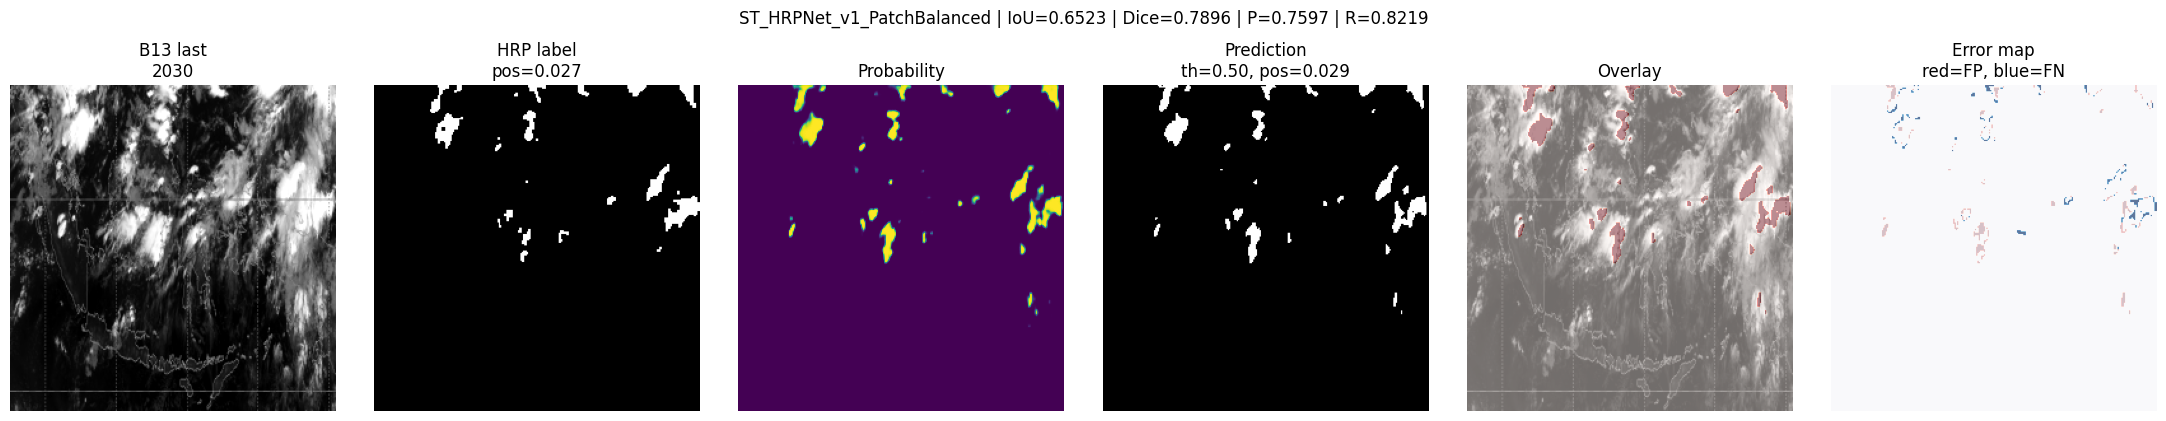

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_001.png


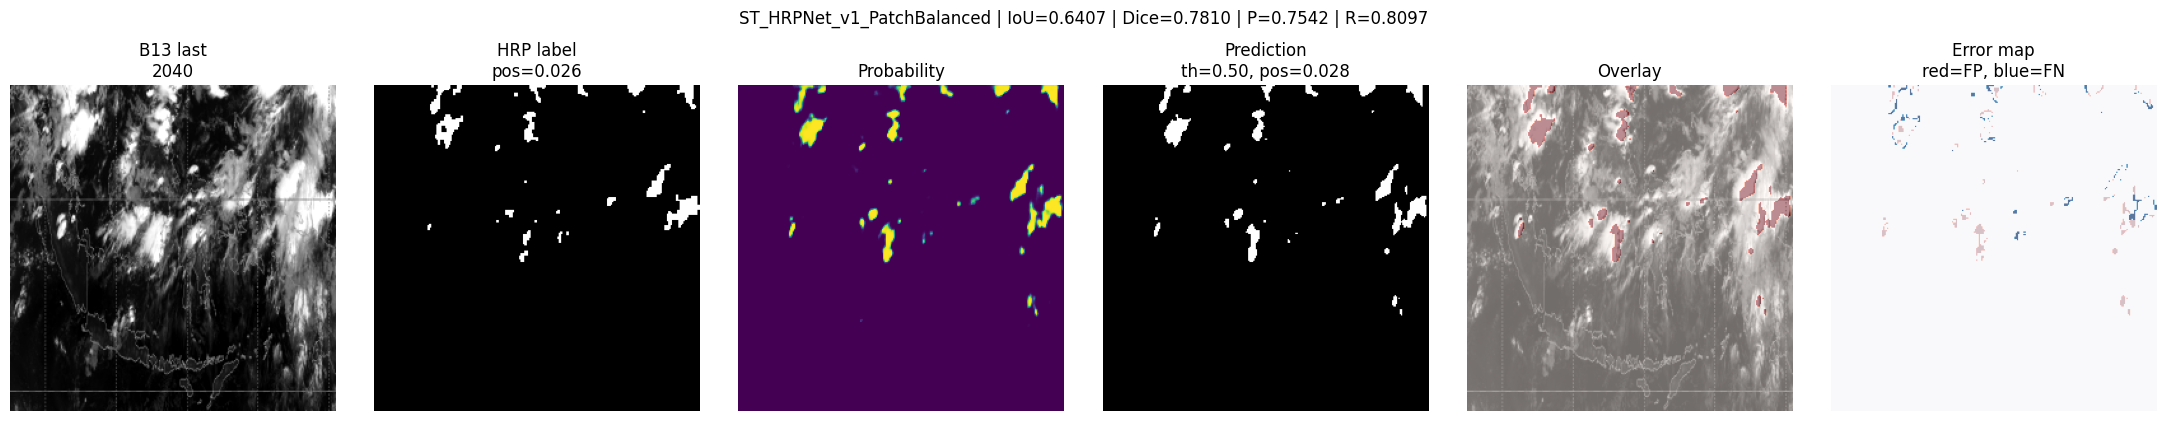

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_002.png


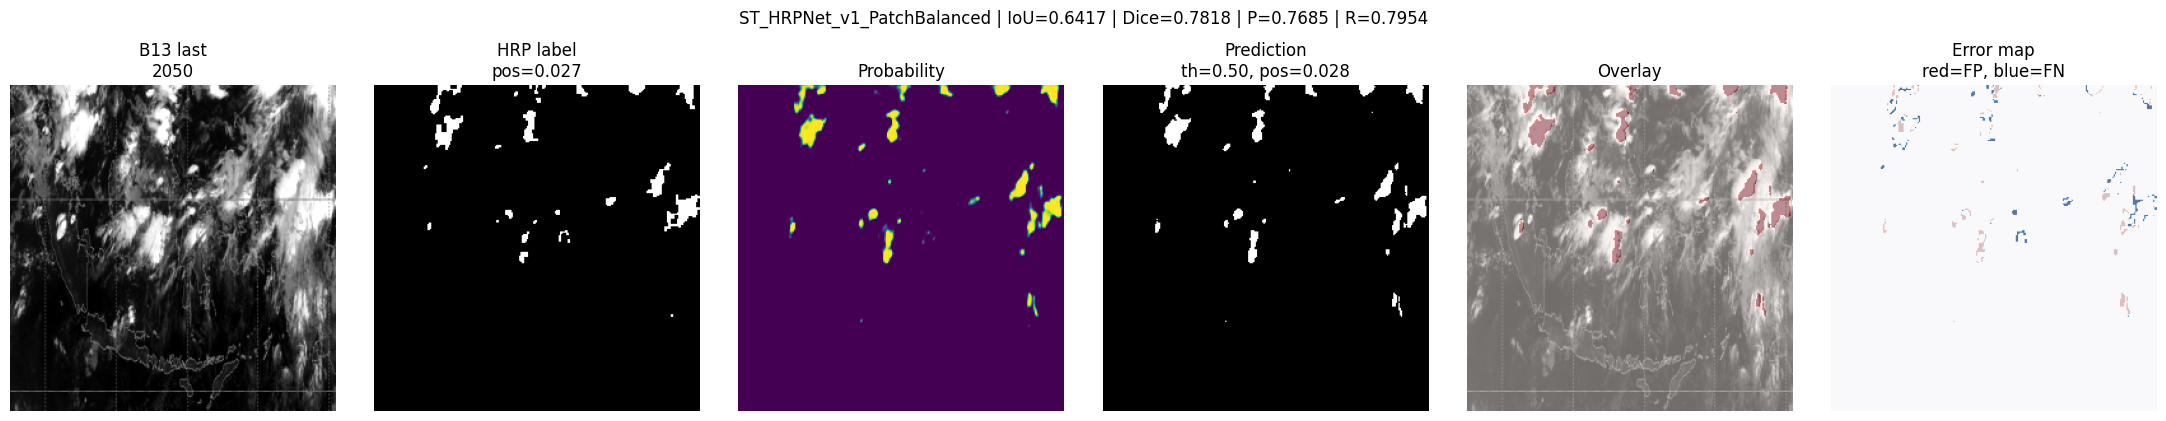

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_003.png


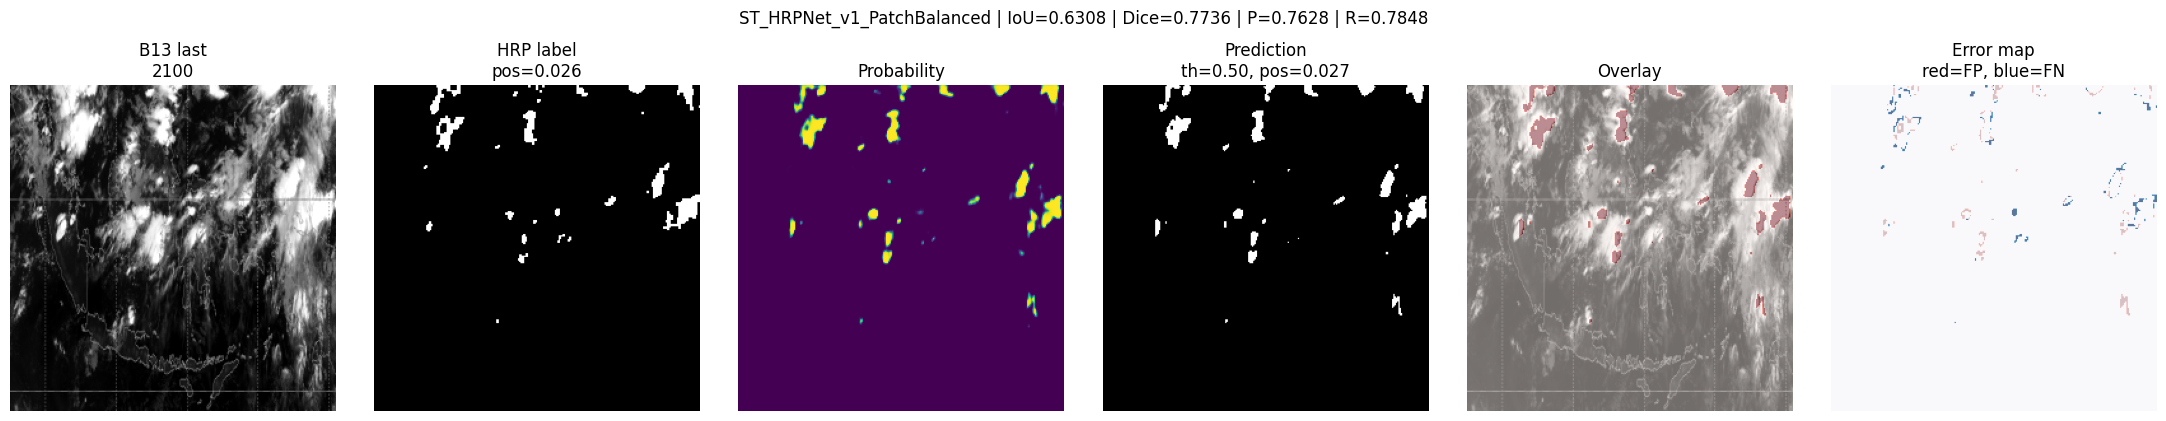

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_004.png


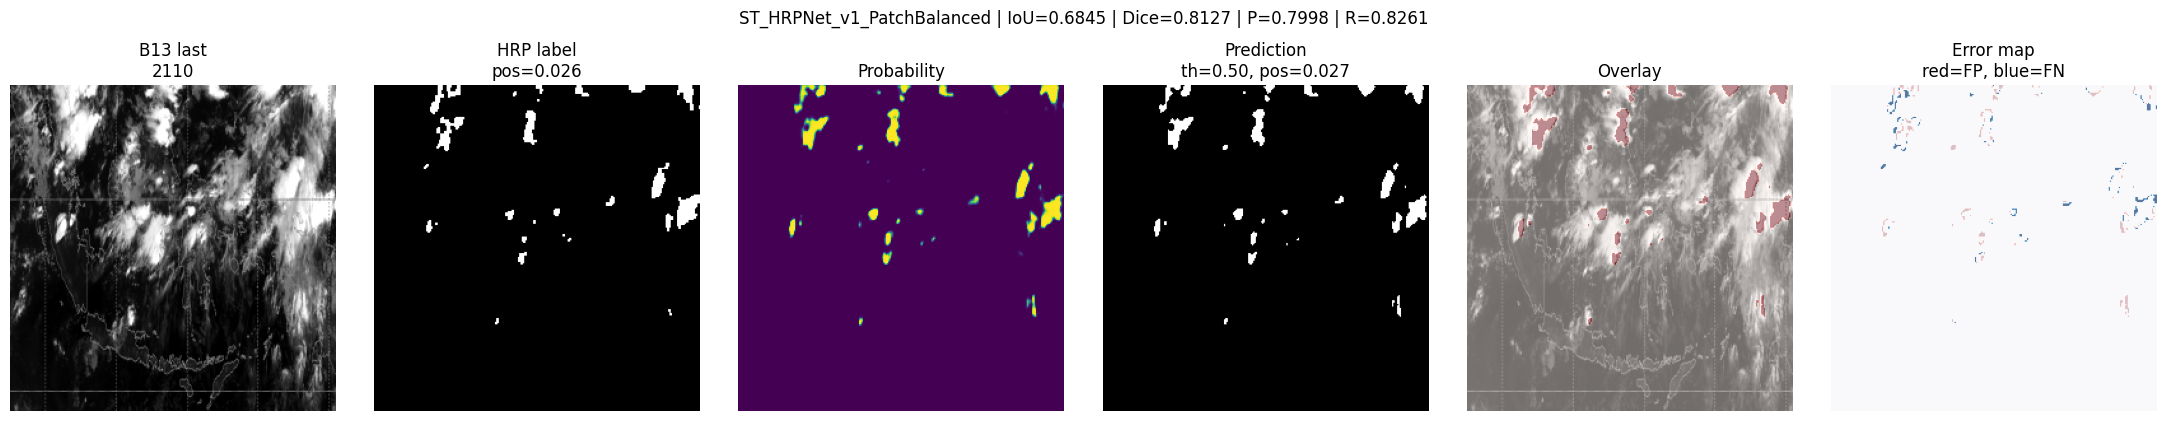

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_prediction_visual_005.png


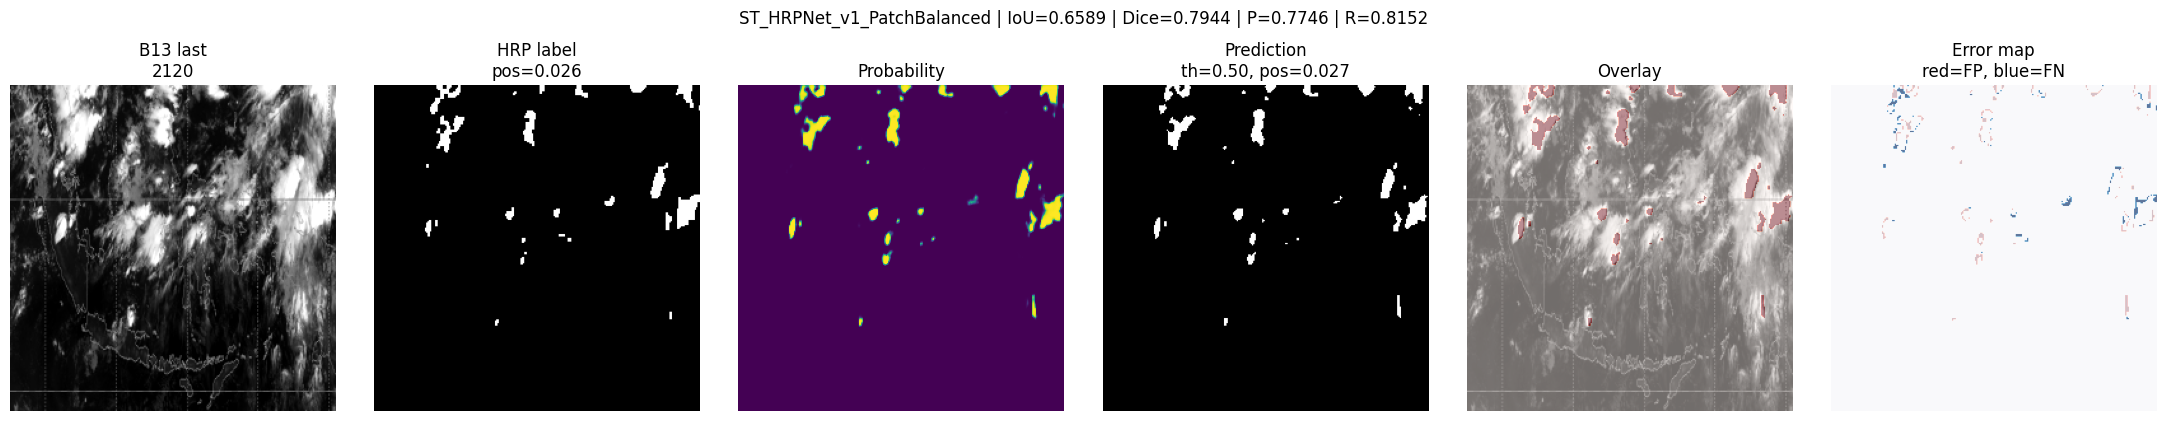

In [30]:
# ============================================================
# 15. VISUALISASI HASIL PREDIKSI FULL IMAGE — SAFE VERSION
# ============================================================

def ensure_results_df():
    global results_df

    if "results_df" in globals() and isinstance(results_df, pd.DataFrame) and len(results_df) > 0:
        return results_df

    candidates = [
        OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv",
        OUTPUT_DIR / "paper_ready_model_comparison_results.csv",
    ]

    for path in candidates:
        if Path(path).exists():
            print(f"results_df tidak ada di memory. Membaca dari: {path}")
            results_df = pd.read_csv(path)
            return results_df

    print("PERINGATAN: results_df belum tersedia dan file CSV evaluasi belum ditemukan.")
    print("Solusi terbaik: jalankan ulang cell #14 terlebih dahulu.")
    print("Untuk sementara visualisasi akan memakai threshold default 0.5.")

    results_df = pd.DataFrame([{
        "model": "ST_HRPNet_v1_PatchBalanced",
        "threshold": 0.5
    }])
    return results_df


def get_threshold_for_model(model_name, default_threshold=0.5):
    df = ensure_results_df()

    if "model" not in df.columns or "threshold" not in df.columns:
        return float(default_threshold)

    row = df[df["model"] == model_name]

    if row.empty:
        alt_names = [
            "ST_HRPNet_v1_PatchBalanced",
            "ST_HRPNet_v1",
            "ST_HRPNet_v1_PatchBalanced_V2"
        ]
        for alt in alt_names:
            row = df[df["model"] == alt]
            if not row.empty:
                print(f"Model {model_name} tidak ditemukan. Memakai threshold dari {alt}.")
                return float(row.iloc[0]["threshold"])

        print(f"Threshold untuk {model_name} tidak ditemukan. Pakai default {default_threshold}.")
        return float(default_threshold)

    th = row.iloc[0]["threshold"]
    if pd.isna(th):
        return float(default_threshold)

    return float(th)


def predict_for_visual(model_obj, X_one, input_type="sequence"):
    if input_type == "2d_last_frame":
        return model_obj.predict(X_one[:, -1, ...], batch_size=1, verbose=0)[0, ..., 0]
    return model_obj.predict(X_one, batch_size=1, verbose=0)[0, ..., 0]


def visualize_prediction(
    idx=0,
    model_obj=st_model,
    model_name="ST_HRPNet_v1_PatchBalanced",
    input_type="sequence",
    threshold=None,
    save=True
):
    if threshold is None:
        threshold = get_threshold_for_model(model_name)

    idx = int(min(max(idx, 0), len(X_test) - 1))

    prob = predict_for_visual(model_obj, X_test[idx:idx+1], input_type=input_type)
    prob = np.nan_to_num(prob, nan=0.0, posinf=1.0, neginf=0.0)
    prob = np.clip(prob, 0.0, 1.0)

    pred = (prob >= threshold).astype(np.float32)

    last_b13 = X_test[idx, -1, ..., INPUT_PRODUCTS.index("b13")]
    gt = y_test[idx, ..., 0].astype(np.float32)

    fp = ((pred == 1) & (gt == 0)).astype(np.float32)
    fn = ((pred == 0) & (gt == 1)).astype(np.float32)

    single_metrics = binary_metrics_np(gt, prob, threshold=threshold)

    fig = plt.figure(figsize=(22, 4))

    plt.subplot(1, 6, 1)
    plt.imshow(last_b13, cmap="gray")
    plt.title(f"B13 last\n{meta_test.iloc[idx]['target_time_code']}")
    plt.axis("off")

    plt.subplot(1, 6, 2)
    plt.imshow(gt, cmap="gray")
    plt.title(f"HRP label\npos={gt.mean():.3f}")
    plt.axis("off")

    plt.subplot(1, 6, 3)
    plt.imshow(prob, cmap="viridis")
    plt.title("Probability")
    plt.axis("off")

    plt.subplot(1, 6, 4)
    plt.imshow(pred, cmap="gray")
    plt.title(f"Prediction\nth={threshold:.2f}, pos={pred.mean():.3f}")
    plt.axis("off")

    plt.subplot(1, 6, 5)
    plt.imshow(last_b13, cmap="gray")
    plt.imshow(pred, alpha=0.45, cmap="Reds")
    plt.title("Overlay")
    plt.axis("off")

    plt.subplot(1, 6, 6)
    plt.imshow(fp, cmap="Reds", alpha=0.65)
    plt.imshow(fn, cmap="Blues", alpha=0.65)
    plt.title("Error map\nred=FP, blue=FN")
    plt.axis("off")

    plt.suptitle(
        f"{model_name} | IoU={single_metrics['iou']:.4f} | "
        f"Dice={single_metrics['dice_f1']:.4f} | "
        f"P={single_metrics['precision']:.4f} | R={single_metrics['recall']:.4f}",
        y=1.04
    )

    plt.tight_layout()

    if save:
        safe_model_name = re.sub(r"[^A-Za-z0-9_\\-]+", "_", str(model_name))
        out_path = OUTPUT_DIR / f"{safe_model_name}_prediction_visual_{idx:03d}.png"
        fig.savefig(out_path, dpi=220, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()


_ = ensure_results_df()
display(results_df)

for i in range(min(6, len(X_test))):
    visualize_prediction(i)

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_loss_curve.png


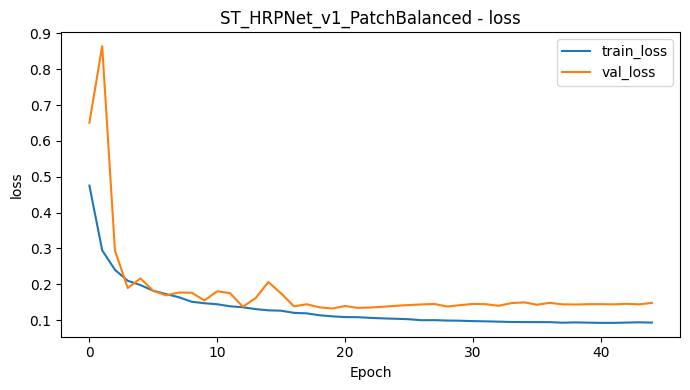

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_iou_coef_curve.png


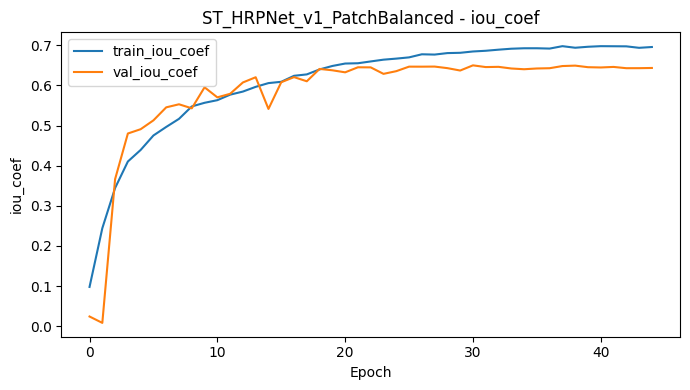

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_dice_coef_curve.png


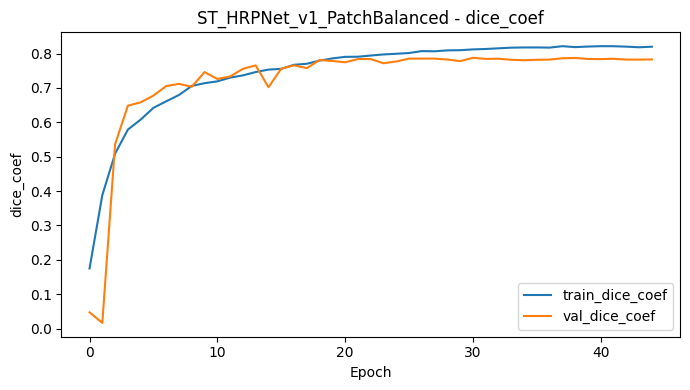

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_precision_at_05_curve.png


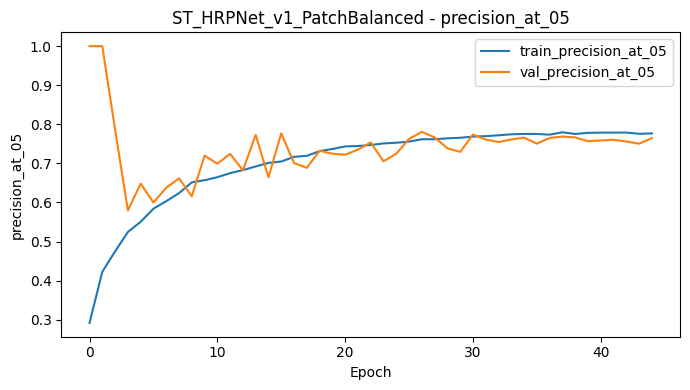

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\ST_HRPNet_v1_PatchBalanced_recall_at_05_curve.png


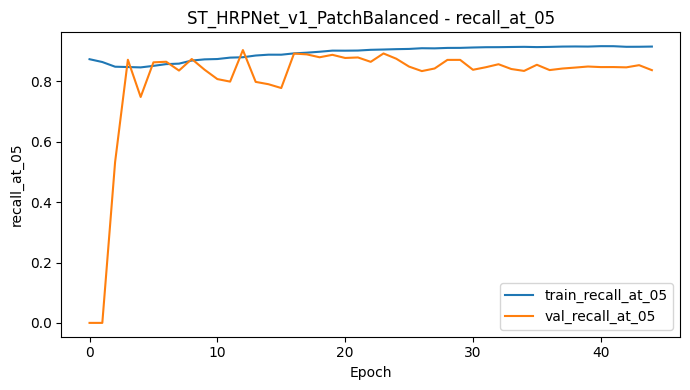

Experiment summary saved: outputs\ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2\jma_snapshot_20260529_0126UTC\experiment_summary_V2.json
{
  "paper_title": "ST-HRPNet v1: Spatiotemporal Learning for Himawari-Derived Heavy Rainfall Potential Segmentation over Indonesia",
  "project_name": "ST_HRPNet_v1_Himawari_Indonesia_PATCHBALANCED_V2",
  "dataset_tag": "jma_snapshot_20260529_0126UTC",
  "jma_list_url": "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html",
  "input_products": [
    "b13",
    "b08",
    "b07",
    "b03"
  ],
  "target_product": "hrp",
  "download_products": [
    "b13",
    "b08",
    "b07",
    "b03",
    "hrp",
    "snd"
  ],
  "sequence_length": 4,
  "image_size": [
    256,
    256
  ],
  "patch_size": 128,
  "n_raw_timestamps_valid": 142,
  "n_sequences": 139,
  "train_sequences": 97,
  "val_sequences": 21,
  "test_sequences": 21,
  "n_train_patches": 1800,
  "n_val_patches": 450,
  "positive_pixel_ratio_all_full": 0.020628895610570908,
  "positive

In [31]:
# ============================================================
# 16. TRAINING CURVES DAN EKSPERIMEN SUMMARY — ULTRA SAFE VERSION
# ============================================================

def safe_var(name, default=None):
    return globals().get(name, default)


def safe_len(name):
    obj = safe_var(name, None)
    if obj is None:
        return None
    try:
        return int(len(obj))
    except Exception:
        return None


def safe_mean(name):
    obj = safe_var(name, None)
    if obj is None:
        return None
    try:
        return float(np.asarray(obj).mean())
    except Exception:
        return None


def find_existing_file(candidates):
    for p in candidates:
        p = Path(p)
        if p.exists():
            return p
    return None


def resolve_results_path():
    """Pastikan results_path tersedia tanpa menyebabkan NameError."""
    global results_path

    if "results_path" in globals():
        try:
            if Path(results_path).exists():
                return Path(results_path)
        except Exception:
            pass

    candidates = [
        OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv",
        OUTPUT_DIR / "paper_ready_model_comparison_results.csv",
    ]

    found = find_existing_file(candidates)
    if found is not None:
        results_path = found
        return results_path

    results_path = OUTPUT_DIR / "paper_ready_model_comparison_results_V2.csv"
    print("PERINGATAN: file hasil evaluasi belum ditemukan.")
    print("Jalankan cell #14 sampai selesai agar CSV hasil evaluasi terbentuk.")
    print("Summary tetap dibuat dengan results_csv sebagai path rencana:", results_path)
    return results_path


def resolve_manifest_path():
    global manifest_path

    if "manifest_path" in globals():
        return Path(manifest_path)

    candidates = sorted(Path(MANIFEST_DIR).glob(f"manifest_{DATASET_TAG}.csv"))
    if candidates:
        manifest_path = candidates[-1]
        return manifest_path

    manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"
    return manifest_path


def resolve_meta_path():
    global meta_path

    if "meta_path" in globals():
        return Path(meta_path)

    meta_path = OUTPUT_DIR / "sequence_metadata.csv"
    return meta_path


def load_history_if_needed(model_name="ST_HRPNet_v1_PatchBalanced"):
    """Ambil training history dari memory atau CSV."""
    global st_history

    if "st_history" in globals() and isinstance(st_history, pd.DataFrame):
        return st_history

    candidates = [
        OUTPUT_DIR / model_name / f"{model_name}_history.csv",
        OUTPUT_DIR / model_name / f"{model_name}_training_log.csv",
    ]

    found = find_existing_file(candidates)
    if found is not None:
        print(f"st_history tidak ada di memory. Membaca history dari: {found}")
        st_history = pd.read_csv(found)
        return st_history

    print("PERINGATAN: st_history belum tersedia dan file history belum ditemukan.")
    print("Kurva training dilewati. Jalankan cell #12 jika ingin membuat kurva.")
    return pd.DataFrame()


def plot_history_safe(history_df, model_name):
    if history_df is None or len(history_df) == 0:
        print("History kosong. Plot training curve dilewati.")
        return

    for metric in ["loss", "iou_coef", "dice_coef", "precision_at_05", "recall_at_05"]:
        if metric not in history_df.columns:
            continue

        plt.figure(figsize=(7, 4))
        plt.plot(history_df[metric], label=f"train_{metric}")

        val_metric = f"val_{metric}"
        if val_metric in history_df.columns:
            plt.plot(history_df[val_metric], label=val_metric)

        plt.title(f"{model_name} - {metric}")
        plt.xlabel("Epoch")
        plt.ylabel(metric)
        plt.legend()
        plt.tight_layout()

        out_path = OUTPUT_DIR / f"{model_name}_{metric}_curve.png"
        plt.savefig(out_path, dpi=220, bbox_inches="tight")
        print("Saved:", out_path)
        plt.show()


# 1) Plot training curve secara aman.
history_df = load_history_if_needed("ST_HRPNet_v1_PatchBalanced")
plot_history_safe(history_df, "ST_HRPNet_v1_PatchBalanced")


# 2) Pastikan path penting aman.
resolved_results_path = resolve_results_path()
resolved_manifest_path = resolve_manifest_path()
resolved_meta_path = resolve_meta_path()


# 3) Load results_df jika memungkinkan.
if "results_df" not in globals():
    if Path(resolved_results_path).exists():
        results_df = pd.read_csv(resolved_results_path)
    else:
        results_df = pd.DataFrame()


# 4) Ringkasan best model jika tabel evaluasi tersedia.
best_model_summary = {}

if isinstance(results_df, pd.DataFrame) and len(results_df) > 0:
    try:
        best_row = results_df.iloc[0].to_dict()

        def safe_float_from_row(key):
            val = best_row.get(key, None)
            if val is None or pd.isna(val):
                return None
            return float(val)

        best_model_summary = {
            "best_model": best_row.get("model", None),
            "best_iou": safe_float_from_row("iou"),
            "best_dice_f1": safe_float_from_row("dice_f1"),
            "best_precision": safe_float_from_row("precision"),
            "best_recall": safe_float_from_row("recall"),
            "best_mcc": safe_float_from_row("mcc"),
            "best_pr_auc": safe_float_from_row("pr_auc"),
            "best_threshold": safe_float_from_row("threshold"),
        }

    except Exception as e:
        print("Peringatan: gagal membuat best_model_summary:", e)
        best_model_summary = {}


# 5) Buat dictionary summary.
# PENTING: Jangan pernah meletakkan if statement di dalam dictionary.
experiment_summary = {
    "paper_title": safe_var("PAPER_TITLE"),
    "project_name": safe_var("PROJECT_NAME"),
    "dataset_tag": safe_var("DATASET_TAG"),
    "jma_list_url": safe_var("JMA_LIST_URL"),
    "input_products": safe_var("INPUT_PRODUCTS"),
    "target_product": safe_var("TARGET_PRODUCT"),
    "download_products": safe_var("DOWNLOAD_PRODUCTS"),
    "sequence_length": safe_var("SEQ_LEN"),
    "image_size": safe_var("IMG_SIZE"),
    "patch_size": safe_var("PATCH_SIZE"),
    "n_raw_timestamps_valid": safe_len("valid_manifest"),
    "n_sequences": safe_len("X"),
    "train_sequences": safe_len("X_train"),
    "val_sequences": safe_len("X_val"),
    "test_sequences": safe_len("X_test"),
    "n_train_patches": safe_len("X_train_patch"),
    "n_val_patches": safe_len("X_val_patch"),
    "positive_pixel_ratio_all_full": safe_mean("y"),
    "positive_pixel_ratio_train_full": safe_mean("y_train"),
    "positive_pixel_ratio_val_full": safe_mean("y_val"),
    "positive_pixel_ratio_test_full": safe_mean("y_test"),
    "positive_pixel_ratio_train_patch": safe_mean("y_train_patch"),
    "positive_pixel_ratio_val_patch": safe_mean("y_val_patch"),
    "loss_pos_weight": float(safe_var("LOSS_POS_WEIGHT")) if safe_var("LOSS_POS_WEIGHT") is not None else None,
    "results_csv": str(resolved_results_path),
    "manifest_csv": str(resolved_manifest_path),
    "sequence_metadata_csv": str(resolved_meta_path),
    "best_model_summary": best_model_summary,
}


# 6) Simpan summary eksperimen.
summary_path = OUTPUT_DIR / "experiment_summary_V2.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, indent=2)

print("Experiment summary saved:", summary_path)
print(json.dumps(experiment_summary, indent=2))


## Kriteria keputusan sebelum lanjut paper

Eksperimen V2 dapat dianggap **lebih layak untuk paper** jika:

1. `predicted_positive_ratio` tidak lagi mendekati 1.0.
2. `precision` naik signifikan dibanding eksperimen awal.
3. `specificity` dan `balanced_accuracy` tidak nol.
4. `MCC` bernilai positif.
5. ST-HRPNet v1 Patch-Balanced mengungguli baseline minimal pada IoU/Dice/PR-AUC atau menunjukkan trade-off terbaik antara recall dan false positive.
6. Visualisasi prediksi menunjukkan pola HRP yang masuk akal secara spasial, bukan seluruh citra menjadi positif.

Jika hasil masih rendah, jangan dipaksakan menjadi klaim "model terbaik". Framing paper dapat diarahkan sebagai **proof-of-concept with controlled threshold and imbalance-aware learning**, lalu dataset diperluas menjadi multi-hari untuk versi paper final.
